# Task 1 - Netflix Data Cleaning & Preparation

In [40]:
# Task 1 - Netflix Data Cleaning & Preparation

import pandas as pd

In [41]:
# Step 1: Import the dataset
df = pd.read_csv("Dataset.csv")
print("Shape (rows, columns):", df.shape)
print(df.head())
print(df.info())

Shape (rows, columns): (8790, 10)
  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, T

In [3]:
# Step 2: Identify and handle missing values
print("\nMissing values (NaN) per column:")
print(df.isnull().sum())

# This dataset has no NaN, but missing info is stored as the text "Not Given".
# Let's count it:
print("\n'Not Given' in director:", (df["director"] == "Not Given").sum())
print("'Not Given' in country:", (df["country"] == "Not Given").sum())

# Replace "Not Given" with "Unknown" so the label is clear for reports
df["director"] = df["director"].replace("Not Given", "Unknown")
df["country"] = df["country"].replace("Not Given", "Unknown")


Missing values (NaN) per column:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

'Not Given' in director: 2588
'Not Given' in country: 287


In [4]:
# Step 3: Remove duplicate records and formatting inconsistencies
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate show_id:", df["show_id"].duplicated().sum())
df = df.drop_duplicates()
df = df.drop_duplicates(subset="show_id")

# Remove extra spaces from all text columns
text_columns = ["type", "title", "director", "country", "rating", "duration", "listed_in"]
for col in text_columns:
    df[col] = df[col].str.strip()

# Convert date_added from text to a real date
df["date_added"] = pd.to_datetime(df["date_added"])
df["year_added"] = df["date_added"].dt.year


Duplicate rows: 0
Duplicate show_id: 0


In [5]:
# Step 4: Standardize columns such as Country, Rating and Type
df["country"] = df["country"].str.title()
df["rating"] = df["rating"].str.upper()
df["type"] = df["type"].replace({"TV show": "TV Show", "Tv Show": "TV Show"})  # keep one spelling only

# Split duration into a number and a unit (e.g. "90 min" -> 90 and "min")
df["duration_value"] = df["duration"].str.split(" ").str[0].astype(int)
df["duration_unit"] = df["duration"].str.split(" ").str[1]

# Check the result
print("\nType counts:")
print(df["type"].value_counts())
print("\nRating counts:")
print(df["rating"].value_counts())


Type counts:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Rating counts:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


**Step 5: Export the cleaned dataset**

Cell chalao aur output dekho. Code ke comments padhke samjho ki kya ho raha hai.

In [6]:
# Step 5: Export the cleaned dataset
df.to_csv("Netflix_Cleaned.csv", index=False)
print("\nCleaned file saved. Final shape:", df.shape)


Cleaned file saved. Final shape: (8790, 13)


---
## Task 2 - Content Type Analysis Dashboard


In [7]:
# Task 2 - Content Type Analysis Dashboard


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# Step 1: Load the cleaned dataset
df = pd.read_csv("Netflix_Cleaned.csv")

In [9]:
# Step 2: Total number of Movies and TV Shows
counts = df["type"].value_counts()
print(counts)
total = len(df)

type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [10]:
# Step 4: Compare proportions (percentage)
percent = counts / total * 100
print("\nPercentage:")
print(percent.round(1))


Percentage:
type
Movie      69.7
TV Show    30.3
Name: count, dtype: float64


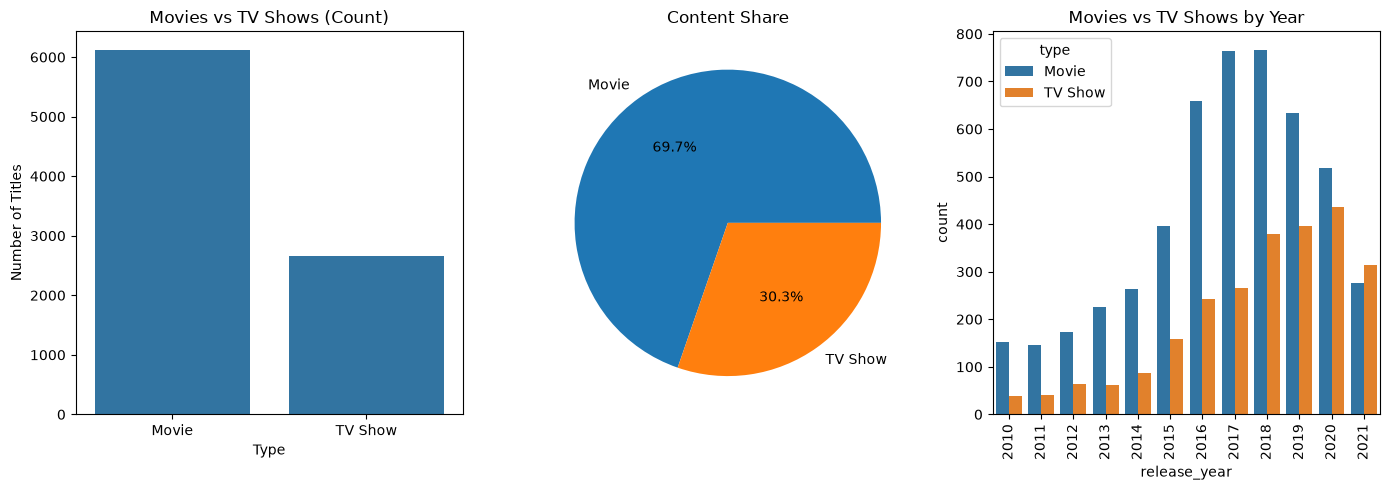

In [11]:
# Step 3: Visualizations
plt.figure(figsize=(14, 5))

# Chart 1: bar chart
plt.subplot(1, 3, 1)
sns.countplot(x="type", data=df)
plt.title("Movies vs TV Shows (Count)")
plt.xlabel("Type")
plt.ylabel("Number of Titles")

# Chart 2: pie chart
plt.subplot(1, 3, 2)
plt.pie(counts, labels=counts.index, autopct="%1.1f%%")
plt.title("Content Share")

# Chart 3: content type by release year (2010 onwards)
plt.subplot(1, 3, 3)
recent = df[df["release_year"] >= 2010]
sns.countplot(x="release_year", hue="type", data=recent)
plt.title("Movies vs TV Shows by Year")
plt.xticks(rotation=90)

plt.tight_layout()
plt.savefig("task2_content_type.png")
plt.show()

In [12]:
# Step 5: Key findings
print("\n--- Key Findings ---")
print("Total titles:", total)
print("Movies:", counts["Movie"], "(", round(percent["Movie"], 1), "% )")
print("TV Shows:", counts["TV Show"], "(", round(percent["TV Show"], 1), "% )")
print("Movies are about", round(counts["Movie"] / counts["TV Show"], 1), "times more than TV Shows.")


--- Key Findings ---
Total titles: 8790
Movies: 6126 ( 69.7 % )
TV Shows: 2664 ( 30.3 % )
Movies are about 2.3 times more than TV Shows.


---
## Task 3 - Country-Wise Netflix Content Analysis

In [13]:
# Task 3 - Country-Wise Netflix Content Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Netflix_Cleaned.csv")

In [14]:
# Step 1: Extract and clean country information
# Remove rows where the country is Unknown (we can't rank an unknown country)
known = df[df["country"] != "Unknown"]
print("Titles with known country:", len(known), "out of", len(df))

Titles with known country: 8503 out of 8790


In [15]:
# Step 2: Content count by country
country_count = known["country"].value_counts()

In [16]:
# Step 3: Top content-producing countries
top10 = country_count.head(10)
print("\nTop 10 countries:")
print(top10)


Top 10 countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


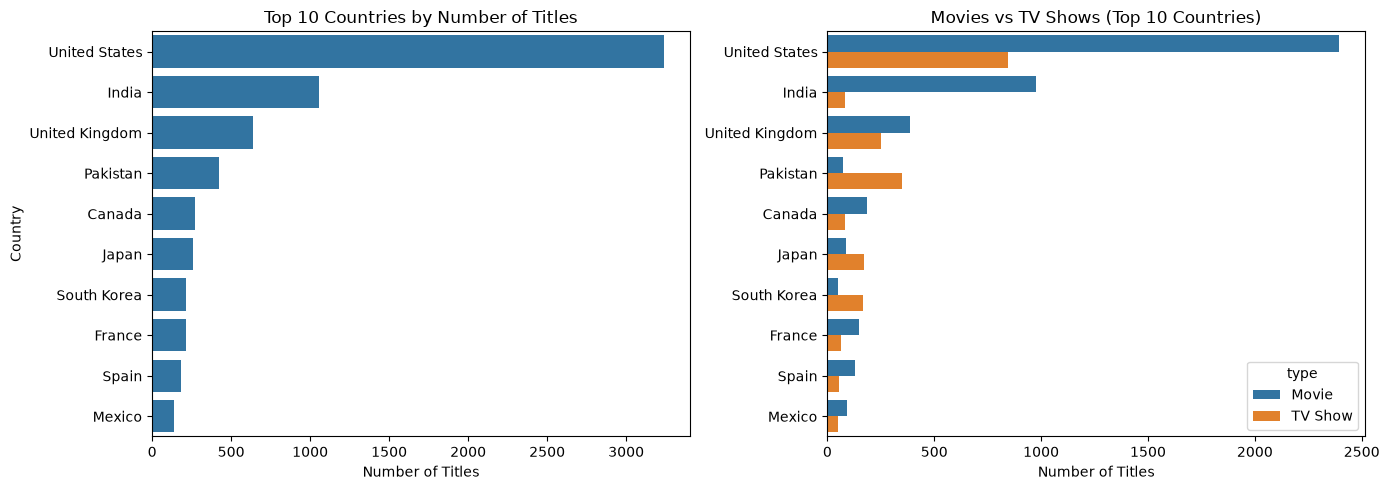


Ranking table:
type            Movie  TV Show  Total
country                              
United States    2395      845   3240
India             976       81   1057
United Kingdom    387      251    638
Pakistan           71      350    421
Canada            187       84    271
Japan              87      172    259
South Korea        49      165    214
France            148       65    213
Spain             129       53    182
Mexico             90       48    138


In [17]:
# Step 4: Charts and rankings
plt.figure(figsize=(14, 5))

# Chart 1: top 10 countries
plt.subplot(1, 2, 1)
sns.barplot(x=top10.values, y=top10.index)
plt.title("Top 10 Countries by Number of Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

# Chart 2: Movies vs TV Shows in the top 10 countries
top10_data = known[known["country"].isin(top10.index)]
plt.subplot(1, 2, 2)
sns.countplot(y="country", hue="type", data=top10_data, order=top10.index)
plt.title("Movies vs TV Shows (Top 10 Countries)")
plt.xlabel("Number of Titles")
plt.ylabel("")

plt.tight_layout()
plt.savefig("task3_country.png")
plt.show()

# Ranking table using groupby
ranking = known.groupby(["country", "type"]).size().unstack(fill_value=0)
ranking["Total"] = ranking["Movie"] + ranking["TV Show"]
ranking = ranking.sort_values("Total", ascending=False).head(10)
print("\nRanking table:")
print(ranking)
ranking.to_csv("task3_country_ranking.csv")

In [18]:
# Step 5: Business insights
share_top2 = (country_count.head(2).sum() / len(known)) * 100
print("\n--- Business Insights ---")
print("Number one country:", top10.index[0], "with", top10.iloc[0], "titles")
print("Number two country:", top10.index[1], "with", top10.iloc[1], "titles")
print("Top 2 countries together make", round(share_top2, 1), "% of all titles with a known country.")
print("Total countries in the data:", known["country"].nunique())


--- Business Insights ---
Number one country: United States with 3240 titles
Number two country: India with 1057 titles
Top 2 countries together make 50.5 % of all titles with a known country.
Total countries in the data: 85


---
## Task 4 - Trend Analysis by Release Year


In [19]:
# Task 4 - Trend Analysis by Release Year

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Netflix_Cleaned.csv")

In [20]:
# Step 1: Organize content by release year
# Old years have very few titles, so we look at 2000 onwards
df = df[df["release_year"] >= 2000]

In [21]:
# Step 2: Yearly content releases
yearly = df.groupby("release_year").size()
print("Titles per release year:")
print(yearly)

yearly_type = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)

Titles per release year:
release_year
2000      37
2001      45
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
dtype: int64


In [22]:
# Step 3: Growth and decline trends
change = yearly.diff()   # difference from the previous year
print("\nYear-on-year change:")
print(change)

peak_year = yearly.idxmax()
print("\nPeak release year:", peak_year, "with", yearly.max(), "titles")
print("Biggest increase:", change.idxmax(), "(+", int(change.max()), ")")
print("Biggest drop:", change.idxmin(), "(", int(change.min()), ")")


Year-on-year change:
release_year
2000      NaN
2001      8.0
2002      6.0
2003      8.0
2004      5.0
2005     16.0
2006     16.0
2007     -8.0
2008     47.0
2009     17.0
2010     40.0
2011     -7.0
2012     51.0
2013     50.0
2014     66.0
2015    203.0
2016    346.0
2017    129.0
2018    116.0
2019   -116.0
2020    -77.0
2021   -361.0
dtype: float64

Peak release year: 2018 with 1146 titles
Biggest increase: 2016 (+ 346 )
Biggest drop: 2021 ( -361 )


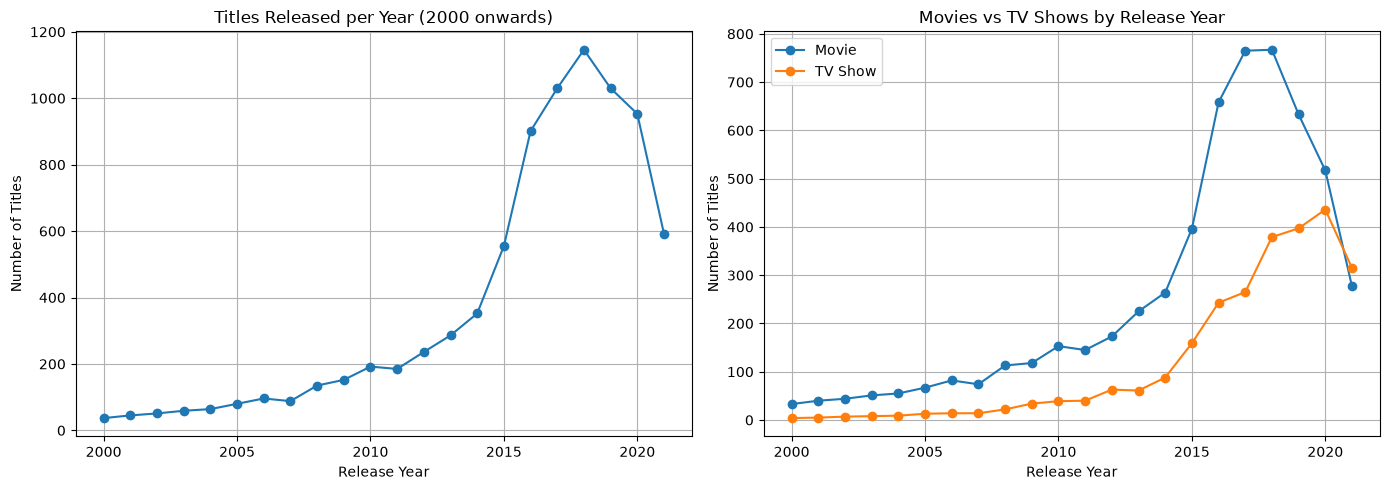

In [23]:
# Step 4: Trend visualizations
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(yearly.index, yearly.values, marker="o")
plt.title("Titles Released per Year (2000 onwards)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(yearly_type.index, yearly_type["Movie"], marker="o", label="Movie")
plt.plot(yearly_type.index, yearly_type["TV Show"], marker="o", label="TV Show")
plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("task4_trend.png")
plt.show()

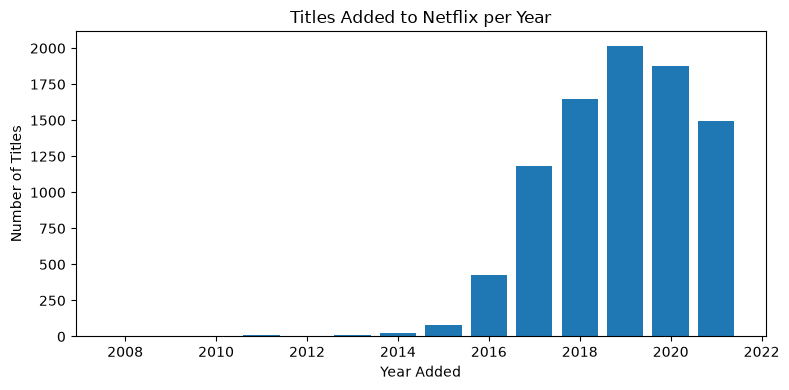

In [24]:
# Extra chart: when did Netflix add the titles?
added = pd.read_csv("Netflix_Cleaned.csv").groupby("year_added").size()
plt.figure(figsize=(8, 4))
plt.bar(added.index, added.values)
plt.title("Titles Added to Netflix per Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("task4_year_added.png")
plt.show()

**Step 5: Business patterns**

Cell chalao aur output dekho. Code ke comments padhke samjho ki kya ho raha hai.

In [25]:
# Step 5: Business patterns
print("\n--- Business Patterns ---")
print("Titles released in 2010:", yearly[2010])
print("Titles released in", peak_year, ":", yearly[peak_year])
print("Last year in data:", yearly.index.max(), "->", yearly.iloc[-1], "titles")
print("(Latest year may look low if the data was collected before the year ended.)")


--- Business Patterns ---
Titles released in 2010: 192
Titles released in 2018 : 1146
Last year in data: 2021 -> 592 titles
(Latest year may look low if the data was collected before the year ended.)


---
## Task 5 - Content Rating & Genre Analysis


In [26]:
# Task 5 - Content Rating & Genre Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Netflix_Cleaned.csv")

In [27]:
# Step 1: Rating categories
rating_count = df["rating"].value_counts()
print("Rating counts:")
print(rating_count)

# Group ratings into simple audience groups using a dictionary
audience = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Teens", "PG": "Teens", "TV-14": "Teens", "PG-13": "Teens",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
    "NR": "Not Rated", "UR": "Not Rated",
}
df["audience"] = df["rating"].map(audience)
print("\nAudience groups:")
print(df["audience"].value_counts())

Rating counts:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Audience groups:
audience
Adults       4007
Teens        3795
Kids          906
Not Rated      82
Name: count, dtype: int64


In [28]:
# Step 2: Most common genres
# 'listed_in' has many genres in one cell, e.g. "Dramas, Comedies".
# We split each cell and count every genre with a dictionary.
genre_count = {}
for cell in df["listed_in"]:
    for genre in cell.split(","):
        genre = genre.strip()
        if genre in genre_count:
            genre_count[genre] = genre_count[genre] + 1
        else:
            genre_count[genre] = 1

genre_series = pd.Series(genre_count).sort_values(ascending=False)
top_genres = genre_series.head(10)
print("\nTop 10 genres:")
print(top_genres)


Top 10 genres:
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
dtype: int64


In [29]:
# Step 3: Compare ratings across content types
rating_type = df.groupby(["rating", "type"]).size().unstack(fill_value=0)
print("\nRatings by content type:")
print(rating_type)


Ratings by content type:
type      Movie  TV Show
rating                  
G            41        0
NC-17         3        0
NR           75        4
PG          287        0
PG-13       490        0
R           797        2
TV-14      1427      730
TV-G        126       94
TV-MA      2062     1143
TV-PG       540      321
TV-Y        131      175
TV-Y7       139      194
TV-Y7-FV      5        1
UR            3        0


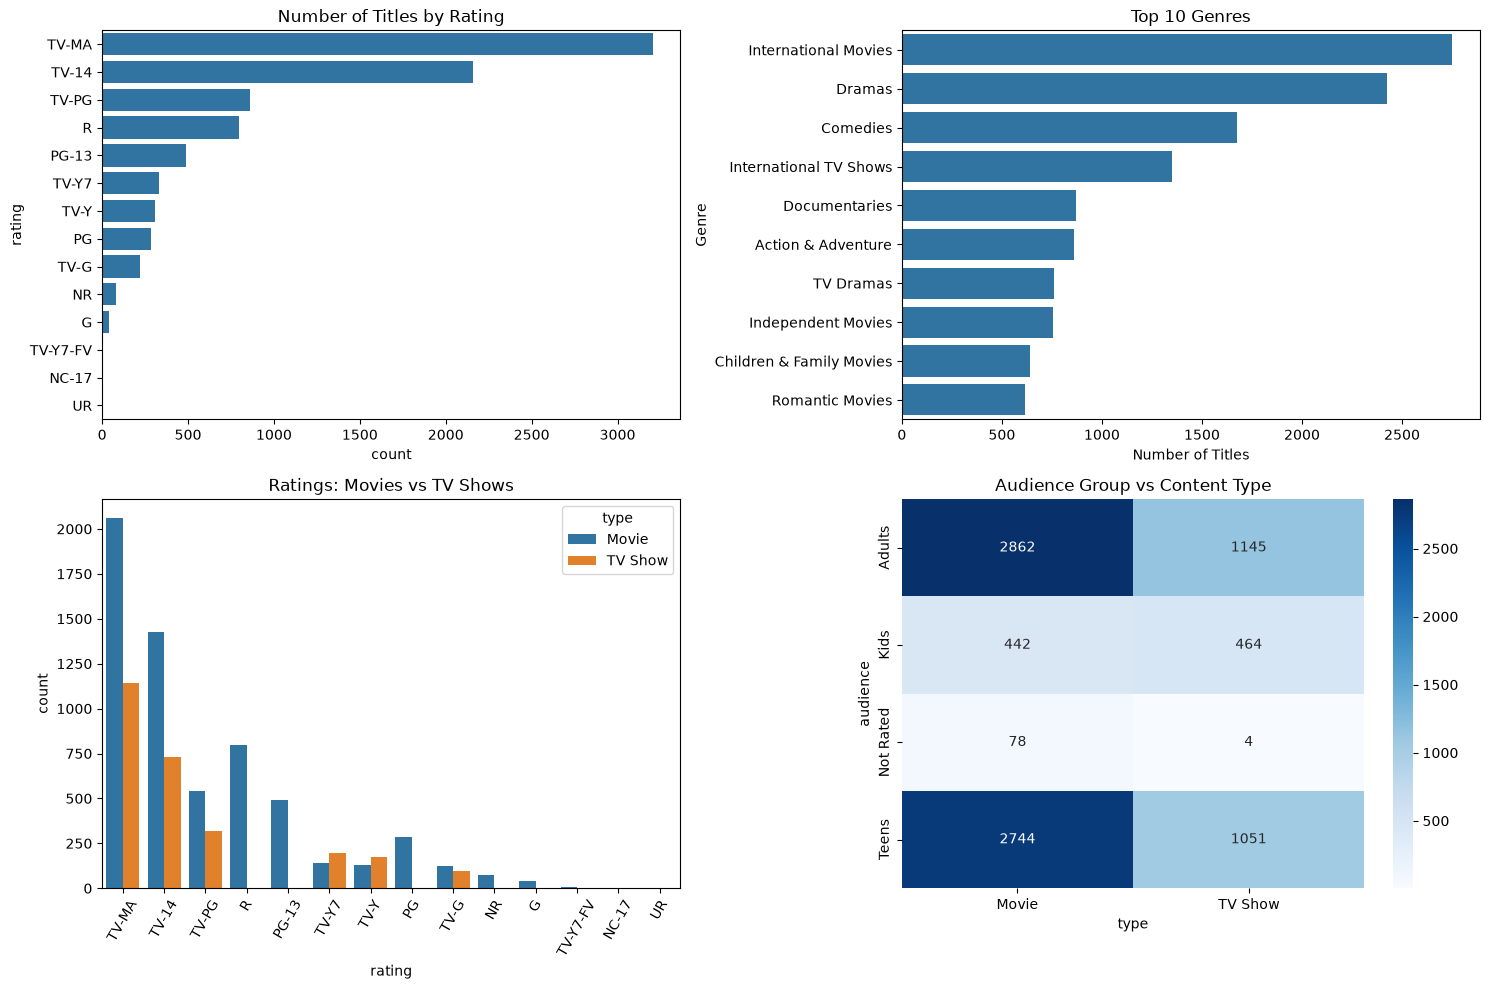

In [30]:
# Step 4: Visualizations
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
sns.countplot(y="rating", data=df, order=rating_count.index)
plt.title("Number of Titles by Rating")

plt.subplot(2, 2, 2)
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Genres")
plt.ylabel("Genre")
plt.xlabel("Number of Titles")

plt.subplot(2, 2, 3)
sns.countplot(x="rating", hue="type", data=df, order=rating_count.index)
plt.title("Ratings: Movies vs TV Shows")
plt.xticks(rotation=60)

plt.subplot(2, 2, 4)
audience_type = df.groupby(["audience", "type"]).size().unstack(fill_value=0)
sns.heatmap(audience_type, annot=True, fmt="d", cmap="Blues")
plt.title("Audience Group vs Content Type")

plt.tight_layout()
plt.savefig("task5_rating_genre.png")
plt.show()

In [31]:
# Step 5: Audience insights
adult_share = (df["audience"] == "Adults").sum() / len(df) * 100
kids_share = (df["audience"] == "Kids").sum() / len(df) * 100
print("\n--- Audience Insights ---")
print("Most common rating:", rating_count.index[0], "(", rating_count.iloc[0], "titles )")
print("Most common genre:", top_genres.index[0], "(", top_genres.iloc[0], "titles )")
print("Adult content share:", round(adult_share, 1), "%")
print("Kids content share:", round(kids_share, 1), "%")


--- Audience Insights ---
Most common rating: TV-MA ( 3205 titles )
Most common genre: International Movies ( 2752 titles )
Adult content share: 45.6 %
Kids content share: 10.3 %


---
## Task 6 - Netflix Business Insights Report


In [32]:
# Task 6 - Netflix Business Insights Report

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Netflix_Cleaned.csv")

In [33]:
# Step 1: Complete exploratory data analysis
print("Rows, columns:", df.shape)
print(df.describe())
print(df.nunique())

movies = df[df["type"] == "Movie"]
shows = df[df["type"] == "TV Show"]

Rows, columns: (8790, 13)
       release_year   year_added  duration_value
count   8790.000000  8790.000000     8790.000000
mean    2014.183163  2018.873606       69.934471
std        8.825466     1.573568       50.794433
min     1925.000000  2008.000000        1.000000
25%     2013.000000  2018.000000        2.000000
50%     2017.000000  2019.000000       88.500000
75%     2019.000000  2020.000000      106.000000
max     2021.000000  2021.000000      312.000000
show_id           8790
type                 2
title             8786
director          4528
country             86
date_added        1713
release_year        74
rating              14
duration           220
listed_in          513
year_added          14
duration_value     210
duration_unit        3
dtype: int64


In [34]:
# Step 2: Key trends and patterns
type_count = df["type"].value_counts()
known = df[df["country"] != "Unknown"]
top_countries = known["country"].value_counts().head(10)
yearly = df[df["release_year"] >= 2000].groupby("release_year").size()
added = df.groupby("year_added").size()
rating_count = df["rating"].value_counts()

genre_count = {}
for cell in df["listed_in"]:
    for genre in cell.split(","):
        genre = genre.strip()
        genre_count[genre] = genre_count.get(genre, 0) + 1
top_genres = pd.Series(genre_count).sort_values(ascending=False).head(10)

top_directors = df[df["director"] != "Unknown"]["director"].value_counts().head(10)

avg_movie_minutes = movies["duration_value"].mean()
season_count = shows["duration_value"].value_counts().sort_index()

In [35]:
# Step 3: Multiple visual dashboards

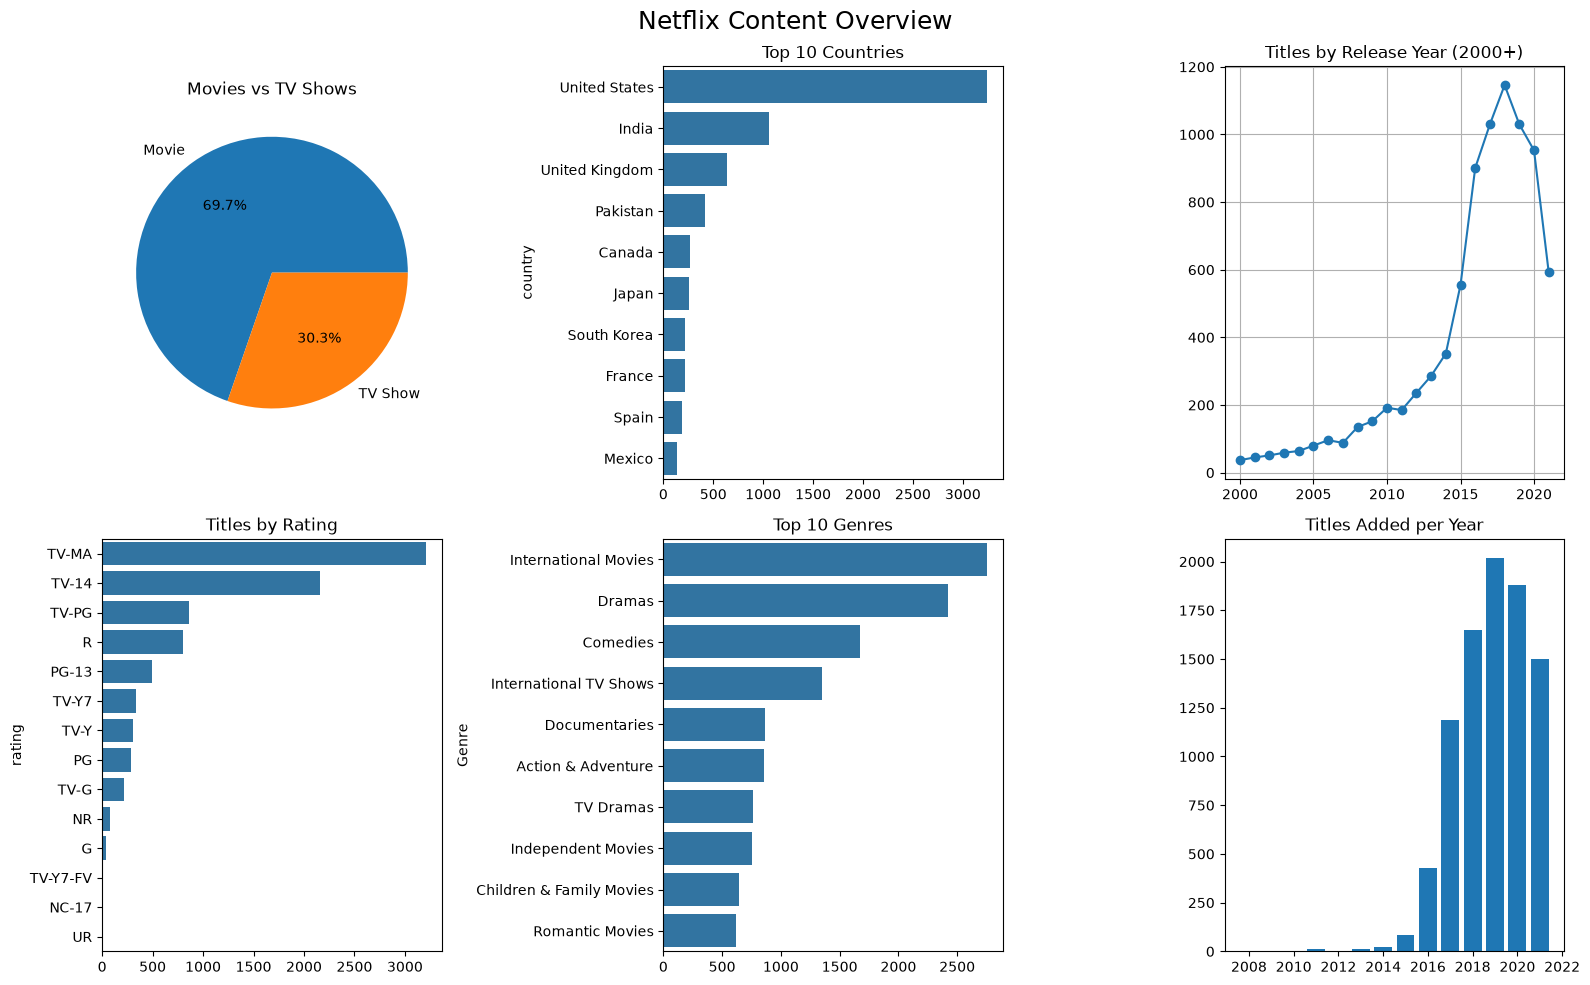

In [36]:
# Dashboard 1: content overview
plt.figure(figsize=(16, 10))
plt.suptitle("Netflix Content Overview", fontsize=18)

plt.subplot(2, 3, 1)
plt.pie(type_count, labels=type_count.index, autopct="%1.1f%%")
plt.title("Movies vs TV Shows")

plt.subplot(2, 3, 2)
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries")

plt.subplot(2, 3, 3)
plt.plot(yearly.index, yearly.values, marker="o")
plt.title("Titles by Release Year (2000+)")
plt.grid(True)

plt.subplot(2, 3, 4)
sns.barplot(x=rating_count.values, y=rating_count.index)
plt.title("Titles by Rating")

plt.subplot(2, 3, 5)
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Genres")
plt.ylabel("Genre")

plt.subplot(2, 3, 6)
plt.bar(added.index, added.values)
plt.title("Titles Added per Year")

plt.tight_layout()
plt.savefig("task6_dashboard1_overview.png")
plt.show()

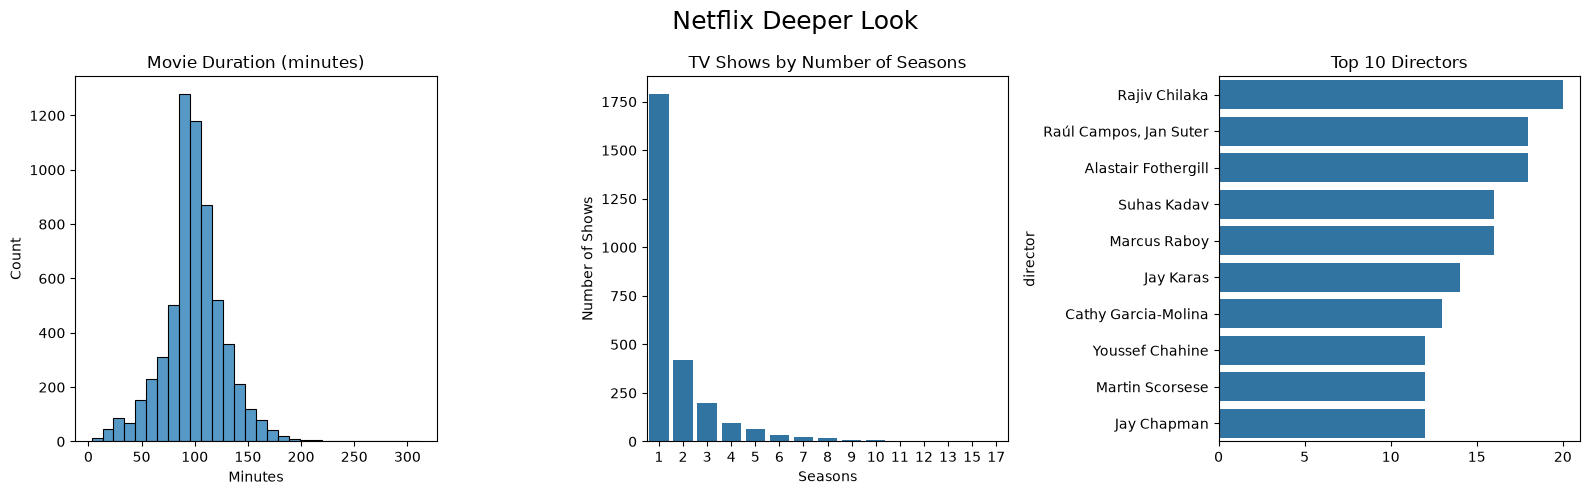

In [37]:
# Dashboard 2: deeper look
plt.figure(figsize=(16, 5))
plt.suptitle("Netflix Deeper Look", fontsize=18)

plt.subplot(1, 3, 1)
sns.histplot(movies["duration_value"], bins=30)
plt.title("Movie Duration (minutes)")
plt.xlabel("Minutes")

plt.subplot(1, 3, 2)
sns.barplot(x=season_count.index, y=season_count.values)
plt.title("TV Shows by Number of Seasons")
plt.xlabel("Seasons")
plt.ylabel("Number of Shows")

plt.subplot(1, 3, 3)
sns.barplot(x=top_directors.values, y=top_directors.index)
plt.title("Top 10 Directors")

plt.tight_layout()
plt.savefig("task6_dashboard2_details.png")
plt.show()

In [38]:
# Step 4: Actionable business insights (numbers come from the data)
total = len(df)
print("\n===== BUSINESS INSIGHTS =====")
print("1. Content mix: Movies =", round(type_count["Movie"] / total * 100, 1), "%, TV Shows =",
      round(type_count.iloc[1] / total * 100, 1), "%")
print("2. Top country:", top_countries.index[0], "-", top_countries.iloc[0], "titles")
print("3. Top 3 countries:", ", ".join(top_countries.index[:3]))
print("4. Most common rating:", rating_count.index[0])
print("5. Most common genre:", top_genres.index[0])
print("6. Average movie length:", round(avg_movie_minutes, 1), "minutes")
print("7. Shows with only 1 season:", round(season_count.iloc[0] / len(shows) * 100, 1), "%")
print("8. Year with most titles added:", added.idxmax(), "(", added.max(), "titles )")
print("9. Titles with unknown director:", (df["director"] == "Unknown").sum())


===== BUSINESS INSIGHTS =====
1. Content mix: Movies = 69.7 %, TV Shows = 30.3 %
2. Top country: United States - 3240 titles
3. Top 3 countries: United States, India, United Kingdom
4. Most common rating: TV-MA
5. Most common genre: International Movies
6. Average movie length: 99.6 minutes
7. Shows with only 1 season: 67.2 %
8. Year with most titles added: 2019 ( 2016 titles )
9. Titles with unknown director: 2588


In [39]:
# Step 5: Save the final report as a text file
with open("task6_final_report.txt", "w") as f:
    f.write("NETFLIX BUSINESS INSIGHTS REPORT\n")
    f.write("================================\n")
    f.write("Total titles analysed: " + str(total) + "\n")
    f.write("Movies: " + str(type_count["Movie"]) + " | TV Shows: " + str(type_count.iloc[1]) + "\n")
    f.write("Top 3 countries: " + ", ".join(top_countries.index[:3]) + "\n")
    f.write("Most common rating: " + rating_count.index[0] + "\n")
    f.write("Most common genre: " + top_genres.index[0] + "\n")
    f.write("Average movie length: " + str(round(avg_movie_minutes, 1)) + " minutes\n")
    f.write("Year with most titles added: " + str(added.idxmax()) + "\n")
print("\nReport saved as task6_final_report.txt")


Report saved as task6_final_report.txt
